Frame read: True (2160, 3840, 3)
Vehicles detected in first frame: 6


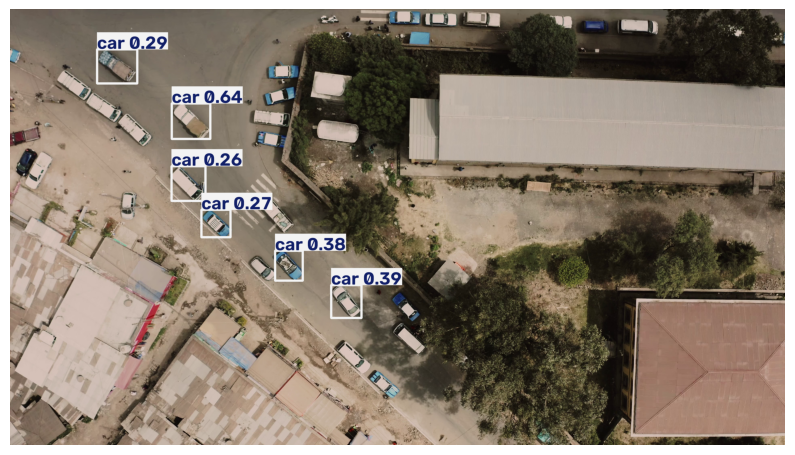

In [1]:
from ultralytics import YOLO
import cv2
import matplotlib.pyplot as plt

cap = cv2.VideoCapture("../data/video/junction.mp4")
ok, frame = cap.read()
cap.release()
print("Frame read:", ok, frame.shape if ok else None)

model = YOLO("yolov8n.pt")   # downloads a small model on first run
result = model(frame, classes=[2, 3, 5, 7], verbose=False)[0]   # car, motorcycle, bus, truck
print("Vehicles detected in first frame:", len(result.boxes))

plt.figure(figsize=(10, 6))
plt.imshow(cv2.cvtColor(result.plot(), cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.show()

In [2]:
from ultralytics import YOLO
import cv2
import matplotlib.pyplot as plt

cap = cv2.VideoCapture("../data/video/junction.mp4")
ok, frame = cap.read()
cap.release()
print("Frame read:", ok, frame.shape if ok else None)

model = YOLO("yolov8n.pt")   # small model, downloads on first run (needs internet)
result = model(frame, classes=[2, 3, 5, 7], verbose=False)[0]   # car, motorcycle, bus, truck
print("Vehicles detected in first frame:", len(result.boxes))

plt.figure(figsize=(10, 6))
plt.imshow(cv2.cvtColor(result.plot(), cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.show()

KeyboardInterrupt: 

In [ ]:
cap = cv2.VideoCapture("../data/video/junction.mp4")
fps = cap.get(cv2.CAP_PROP_FPS)
n = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
print(f"FPS {fps:.1f} | frames {n} | duration {n/fps:.1f} s")
cap.release()

h, w = frame.shape[:2]
plt.figure(figsize=(12, 7))
plt.imshow(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
plt.xticks(range(0, w, 500))
plt.yticks(range(0, h, 500))
plt.grid(True, color="yellow", alpha=0.5)
plt.title("Pixel coordinates (x across, y down)")
plt.show()

In [ ]:
REGION_A = (150, 200, 1150, 1150)
REGION_B = (1150, 200, 2100, 2000)

preview = frame.copy()
for region, color in [(REGION_A, (255, 0, 0)), (REGION_B, (0, 0, 255))]:
    cv2.rectangle(preview, (region[0], region[1]), (region[2], region[3]), color, 12)

plt.figure(figsize=(12, 7))
plt.imshow(cv2.cvtColor(preview, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.show()

In [5]:
import pandas as pd

VIDEO_PATH = "../data/video/junction.mp4"
WINDOW_SECONDS = 5
FRAME_STEP = 2                 # process every 2nd frame
VEHICLES = [2, 3, 5, 7]        # car, motorcycle, bus, truck

def inside(cx, cy, r):
    return r[0] <= cx <= r[2] and r[1] <= cy <= r[3]

cap = cv2.VideoCapture(VIDEO_PATH)
fps = cap.get(cv2.CAP_PROP_FPS)
frames_per_window = int(fps * WINDOW_SECONDS)

model = YOLO("yolov8n.pt")     # fresh model, so the tracker starts clean
rows, ids_a, ids_b = [], set(), set()
frame_no = 0

while True:
    ok, fr = cap.read()
    if not ok:
        break
    if frame_no % FRAME_STEP == 0:
        res = model.track(fr, persist=True, classes=VEHICLES, imgsz=1280, verbose=False)[0]
        if res.boxes.id is not None:
            for box, tid in zip(res.boxes.xywh.tolist(), res.boxes.id.tolist()):
                cx, cy = box[0], box[1]
                if inside(cx, cy, REGION_A):
                    ids_a.add(int(tid))
                elif inside(cx, cy, REGION_B):
                    ids_b.add(int(tid))
    frame_no += 1
    if frame_no % frames_per_window == 0:
        rows.append({"window_start_sec": round(frame_no / fps - WINDOW_SECONDS, 1),
                     "window_len_sec": WINDOW_SECONDS,
                     "road_a_count": len(ids_a), "road_b_count": len(ids_b)})
        ids_a, ids_b = set(), set()

if frame_no % frames_per_window != 0:     # last, shorter window
    rows.append({"window_start_sec": round((frame_no // frames_per_window) * WINDOW_SECONDS, 1),
                 "window_len_sec": round((frame_no % frames_per_window) / fps, 1),
                 "road_a_count": len(ids_a), "road_b_count": len(ids_b)})
cap.release()

counts = pd.DataFrame(rows)
counts.to_csv("../results/video_counts_demo.csv", index=False)
counts

NameError: name 'REGION_A' is not defined

In [7]:
import time
import cv2
import pandas as pd
from ultralytics import YOLO

VIDEO_PATH = "../data/video/junction.mp4"
WINDOW_SECONDS = 5
FRAME_STEP = 3                 # process every 3rd frame
SCALE = 0.5                    # shrink 4K frames to half size
VEHICLES = [2, 3, 5, 7]

def scaled(r):
    return tuple(int(v * SCALE) for v in r)

RA, RB = scaled(REGION_A), scaled(REGION_B)

def inside(cx, cy, r):
    return r[0] <= cx <= r[2] and r[1] <= cy <= r[3]

cap = cv2.VideoCapture(VIDEO_PATH)
fps = cap.get(cv2.CAP_PROP_FPS)
frames_per_window = int(fps * WINDOW_SECONDS)

model = YOLO("yolov8n.pt")
rows, ids_a, ids_b = [], set(), set()
frame_no, processed, start = 0, 0, time.time()

while True:
    ok, fr = cap.read()
    if not ok:
        break
    if frame_no % FRAME_STEP == 0:
        small = cv2.resize(fr, None, fx=SCALE, fy=SCALE)
        res = model.track(small, persist=True, classes=VEHICLES, imgsz=960, verbose=False)[0]
        if res.boxes.id is not None:
            for box, tid in zip(res.boxes.xywh.tolist(), res.boxes.id.tolist()):
                if inside(box[0], box[1], RA):
                    ids_a.add(int(tid))
                elif inside(box[0], box[1], RB):
                    ids_b.add(int(tid))
        processed += 1
        if processed % 20 == 0:
            print(f"frame {frame_no}/538 | {time.time() - start:.0f} s elapsed")
    frame_no += 1
    if frame_no % frames_per_window == 0:
        rows.append({"window_start_sec": round(frame_no / fps - WINDOW_SECONDS, 1),
                     "window_len_sec": WINDOW_SECONDS,
                     "road_a_count": len(ids_a), "road_b_count": len(ids_b)})
        ids_a, ids_b = set(), set()

if frame_no % frames_per_window != 0:
    rows.append({"window_start_sec": round((frame_no // frames_per_window) * WINDOW_SECONDS, 1),
                 "window_len_sec": round((frame_no % frames_per_window) / fps, 1),
                 "road_a_count": len(ids_a), "road_b_count": len(ids_b)})
cap.release()

counts = pd.DataFrame(rows)
counts.to_csv("../results/video_counts_demo.csv", index=False)
print(f"Done in {time.time() - start:.0f} s")
counts

frame 57/538 | 8 s elapsed
frame 117/538 | 15 s elapsed
frame 177/538 | 22 s elapsed
frame 237/538 | 29 s elapsed
frame 297/538 | 37 s elapsed
frame 357/538 | 43 s elapsed
frame 417/538 | 49 s elapsed
frame 477/538 | 56 s elapsed
frame 537/538 | 63 s elapsed
Done in 63 s


,window_start_sec,window_len_sec,road_a_count,road_b_count
0,0.0,5.0,1,0
1,5.0,5.0,1,0
2,10.0,5.0,0,0
3,15.0,5.0,0,0
4,20.0,2.4,0,0


In [6]:
import cv2
import pandas as pd
import matplotlib.pyplot as plt
from ultralytics import YOLO

REGION_A = (150, 200, 1150, 1150)
REGION_B = (1150, 200, 2100, 2000)
print("Regions defined:", REGION_A, REGION_B)

Regions defined: (150, 200, 1150, 1150) (1150, 200, 2100, 2000)


yolov8n.pt imgsz=640: 18 detections, 16 vehicle-type | 0.3 s | classes: ['car', 'person', 'truck']
yolov8n.pt imgsz=1280: 23 detections, 21 vehicle-type | 0.3 s | classes: ['bus', 'car', 'person', 'truck']
yolov8n.pt imgsz=1920: 37 detections, 23 vehicle-type | 0.7 s | classes: ['bottle', 'broccoli', 'bus', 'car', 'cell phone', 'person', 'traffic light', 'truck']
yolov8s.pt imgsz=640: 18 detections, 15 vehicle-type | 0.4 s | classes: ['bus', 'car', 'person', 'traffic light', 'truck']
yolov8s.pt imgsz=1280: 30 detections, 25 vehicle-type | 0.7 s | classes: ['broccoli', 'bus', 'car', 'cell phone', 'person', 'traffic light']
yolov8s.pt imgsz=1920: 28 detections, 14 vehicle-type | 1.5 s | classes: ['bottle', 'bus', 'car', 'cell phone', 'person', 'toilet']


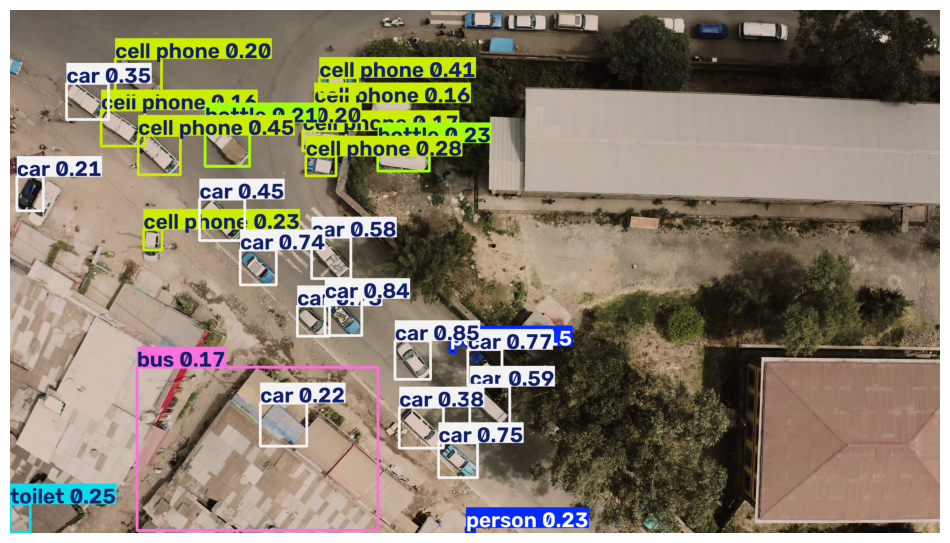

In [8]:
import time
import cv2
import matplotlib.pyplot as plt
from ultralytics import YOLO

cap = cv2.VideoCapture("../data/video/junction.mp4")
ok, frame = cap.read()
cap.release()

for weights in ["yolov8n.pt", "yolov8s.pt"]:
    m = YOLO(weights)
    for size in [640, 1280, 1920]:
        t = time.time()
        r = m(frame, imgsz=size, conf=0.15, verbose=False)[0]
        names = [m.names[int(c)] for c in r.boxes.cls.tolist()]
        veh = sum(n in ("car", "motorcycle", "bus", "truck") for n in names)
        print(f"{weights} imgsz={size}: {len(names)} detections, {veh} vehicle-type | "
              f"{time.time() - t:.1f} s | classes: {sorted(set(names))}")

plt.figure(figsize=(12, 7))
plt.imshow(cv2.cvtColor(r.plot(), cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.show()

Frame read: True (2160, 3840, 3)
Vehicles detected: 6


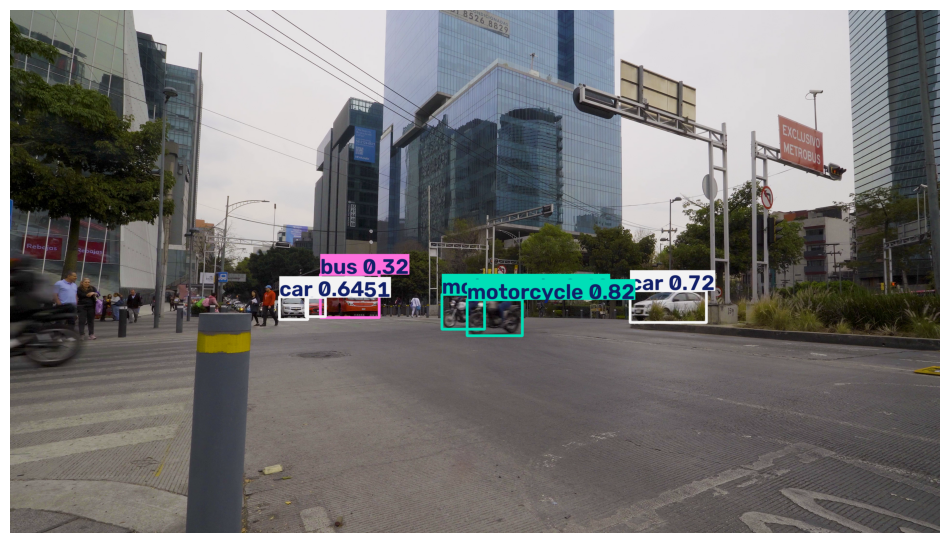

In [9]:
import cv2
import matplotlib.pyplot as plt
from ultralytics import YOLO

cap = cv2.VideoCapture("../data/video/junction2.mp4")
ok, frame = cap.read()
cap.release()
print("Frame read:", ok, frame.shape if ok else None)

model = YOLO("yolov8n.pt")
r = model(frame, classes=[2, 3, 5, 7], imgsz=960, conf=0.25, verbose=False)[0]
print("Vehicles detected:", len(r.boxes))

plt.figure(figsize=(12, 7))
plt.imshow(cv2.cvtColor(r.plot(), cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.show()

In [10]:
import time
import cv2
import pandas as pd
from ultralytics import YOLO

VIDEO_PATH = "../data/video/junction2.mp4"
WINDOW_SECONDS = 5
FRAME_STEP = 3          # process every 3rd frame
SCALE = 0.5             # shrink 4K frames to half size
VEHICLES = [2, 3, 5, 7]
MIN_MOVE = 40           # pixels (in the shrunk frame) to count as moving sideways
MIN_SEEN = 3            # an ID must appear in at least 3 processed frames

cap = cv2.VideoCapture(VIDEO_PATH)
fps = cap.get(cv2.CAP_PROP_FPS)
total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
print(f"FPS {fps:.1f} | frames {total} | duration {total / fps:.1f} s")
frames_per_window = int(fps * WINDOW_SECONDS)

model = YOLO("yolov8n.pt")
tracks, rows = {}, []          # tracks: id -> [first_x, last_x, times_seen]
frame_no, processed, start = 0, 0, time.time()

def close_window(start_sec, length_sec):
    right = left = still = 0
    for first_x, last_x, seen in tracks.values():
        if seen < MIN_SEEN:
            continue
        dx = last_x - first_x
        if dx > MIN_MOVE:
            right += 1
        elif dx < -MIN_MOVE:
            left += 1
        else:
            still += 1
    rows.append({"window_start_sec": round(start_sec, 1),
                 "window_len_sec": round(length_sec, 1),
                 "moving_right": right, "moving_left": left,
                 "not_moving_sideways": still,
                 "total_vehicles": right + left + still})
    tracks.clear()

while True:
    ok, fr = cap.read()
    if not ok:
        break
    if frame_no % FRAME_STEP == 0:
        small = cv2.resize(fr, None, fx=SCALE, fy=SCALE)
        res = model.track(small, persist=True, classes=VEHICLES, imgsz=960,
                          conf=0.3, verbose=False)[0]
        if res.boxes.id is not None:
            for box, tid in zip(res.boxes.xywh.tolist(), res.boxes.id.tolist()):
                x, tid = box[0], int(tid)
                if tid in tracks:
                    tracks[tid][1] = x
                    tracks[tid][2] += 1
                else:
                    tracks[tid] = [x, x, 1]
        processed += 1
        if processed % 20 == 0:
            print(f"frame {frame_no}/{total} | {time.time() - start:.0f} s elapsed")
    frame_no += 1
    if frame_no % frames_per_window == 0:
        close_window(frame_no / fps - WINDOW_SECONDS, WINDOW_SECONDS)

if frame_no % frames_per_window != 0:
    close_window((frame_no // frames_per_window) * WINDOW_SECONDS,
                 (frame_no % frames_per_window) / fps)
cap.release()

counts = pd.DataFrame(rows)
counts.to_csv("../results/video_counts_demo.csv", index=False)
print(f"Done in {time.time() - start:.0f} s")
counts

FPS 24.0 | frames 2657 | duration 110.8 s
frame 57/2657 | 8 s elapsed
frame 117/2657 | 14 s elapsed
frame 177/2657 | 21 s elapsed
frame 237/2657 | 28 s elapsed
frame 297/2657 | 34 s elapsed
frame 357/2657 | 41 s elapsed
frame 417/2657 | 48 s elapsed
frame 477/2657 | 55 s elapsed
frame 537/2657 | 61 s elapsed
frame 597/2657 | 69 s elapsed
frame 657/2657 | 75 s elapsed
frame 717/2657 | 83 s elapsed
frame 777/2657 | 90 s elapsed
frame 837/2657 | 97 s elapsed
frame 897/2657 | 104 s elapsed
frame 957/2657 | 110 s elapsed
frame 1017/2657 | 117 s elapsed
frame 1077/2657 | 123 s elapsed
frame 1137/2657 | 130 s elapsed
frame 1197/2657 | 136 s elapsed
frame 1257/2657 | 143 s elapsed
frame 1317/2657 | 149 s elapsed
frame 1377/2657 | 156 s elapsed
frame 1437/2657 | 163 s elapsed
frame 1497/2657 | 169 s elapsed
frame 1557/2657 | 176 s elapsed
frame 1617/2657 | 183 s elapsed
frame 1677/2657 | 189 s elapsed
frame 1737/2657 | 196 s elapsed
frame 1797/2657 | 203 s elapsed
frame 1857/2657 | 209 s elapse

,window_start_sec,window_len_sec,moving_right,moving_left,not_moving_sideways,total_vehicles
0,-0.0,5.0,0,3,2,5
1,4.9,5.0,0,3,2,5
2,9.9,5.0,0,2,2,4
3,14.9,5.0,0,1,2,3
4,19.8,5.0,1,3,2,6
5,24.8,5.0,0,5,2,7
6,29.7,5.0,2,2,5,9
7,34.7,5.0,0,6,2,8
8,39.7,5.0,0,4,2,6
9,44.6,5.0,5,3,1,9
